In [1]:
import sys
if 'google.colab' in sys.modules:
  !pip install -q dtreeviz
!pip install interpret six graphviz pydotplus


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.3/102.3 kB 3.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.0/4.0 MB 21.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.0/48.0 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.6/15.6 MB 77.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 90.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 88.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 62.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 800.1/800.1 kB 41.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 623.8/623.8 kB 38.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 95.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 283.5/283.5 kB 18.1 MB/s eta 0:00:00
  Created wheel for dash-cytoscape: filename=dash_cytoscape-1.0.2-py3-none-any.whl size=

Carga de datos

In [2]:
import pandas as pd

base = "https://raw.githubusercontent.com/nicolas-pueyo/ia-explicable/main/data/"
train = pd.read_csv(base + "train.csv")
test = pd.read_csv(base + "test.csv")
dic = pd.read_excel(base + "data-dictionary.xlsx")

id_col = 'row_id'
target_col = 'payment_difficulty_next_month'

credit_y = train[target_col]
credit_X = train.drop(columns=[target_col, id_col])

categorical_cols = [
    'sex',
    'education',
    'marital_status',
    'repayment_assistance_plan'
]

numeric_cols = [col for col in credit_X.columns if col not in categorical_cols]

Preprocesado

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_cols),
        ("num", "passthrough", numeric_cols)
    ]
)

tree_clf = DecisionTreeClassifier(random_state=42)

model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", tree_clf)
])

Búsqueda de hiperparámetros

In [4]:
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid = {
    'classifier__max_depth': [3, 4], # valores pequeños para interpretabilidad
    'classifier__min_samples_leaf': [20, 50, 100],
    'classifier__criterion': ['gini', 'entropy']
}

grid_search = GridSearchCV(
    estimator=model_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    refit=True # Entrena un modelo final con los mejores parámetros utilizando todo el conjunto de entrenamiento
)

grid_search.fit(credit_X, credit_y)
best_pipeline = grid_search.best_estimator_

In [5]:
# Mostrar los mejores hiperparámetros encontrados por el Grid Search
print("==================================================")
print("  MEJORES HIPERPARÁMETROS SELECCIONADOS POR CV")
print("==================================================")
for param, value in grid_search.best_params_.items():
    # Limpiamos el prefijo del clasificador para que sea más legible
    clean_param = param.replace('classifier__', '')
    print(f"-> {clean_param}: {value}")
print("==================================================")
print(f"Mejor puntuación obtenida (ROC AUC): {grid_search.best_score_:.4f}")

  MEJORES HIPERPARÁMETROS SELECCIONADOS POR CV
-> criterion: entropy
-> max_depth: 4
-> min_samples_leaf: 100
Mejor puntuación obtenida (ROC AUC): 0.7473


Resultados de la búsqueda

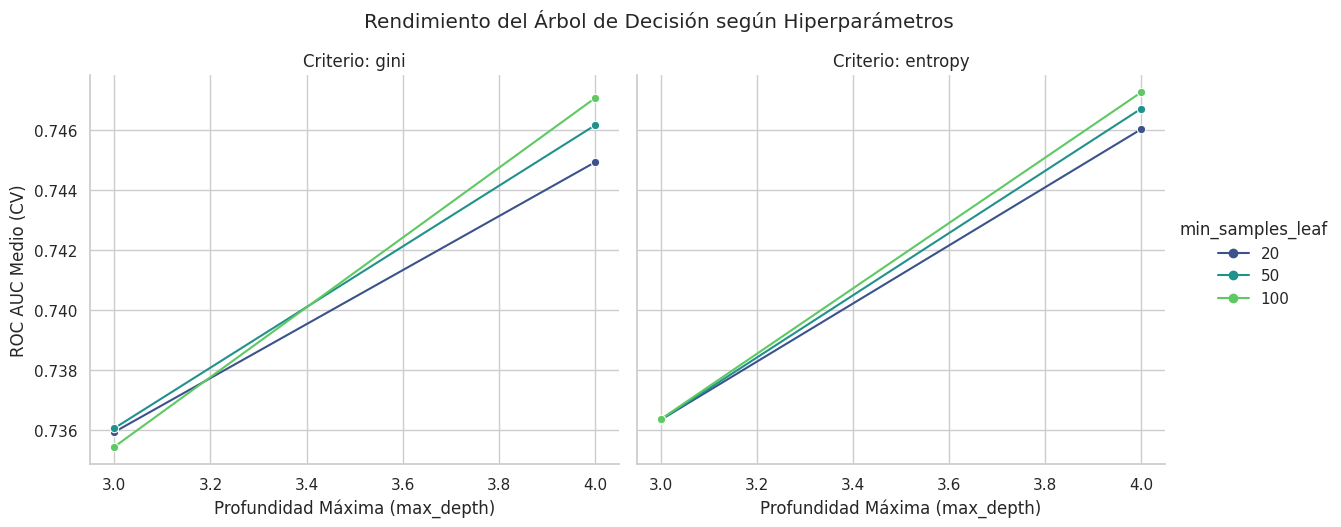

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

results_df = pd.DataFrame(grid_search.cv_results_)

results_df['max_depth'] = results_df['param_classifier__max_depth'].astype(int)
results_df['min_samples_leaf'] = results_df['param_classifier__min_samples_leaf'].astype(str)
results_df['criterion'] = results_df['param_classifier__criterion']
results_df['roc_auc'] = results_df['mean_test_score']

sns.set_theme(style="whitegrid")
g = sns.relplot(
    data=results_df,
    kind="line",
    x="max_depth",
    y="roc_auc",
    hue="min_samples_leaf",
    col="criterion",
    marker="o",
    height=5,
    aspect=1.2,
    palette="viridis"
)

g.set_axis_labels("Profundidad Máxima (max_depth)", "ROC AUC Medio (CV)")
g.set_titles("Criterio: {col_name}")
g.fig.suptitle("Rendimiento del Árbol de Decisión según Hiperparámetros", y=1.05)

plt.savefig("hyperparameter_tuning.png", dpi=300, bbox_inches="tight")
plt.show()

In [7]:
tabla_grid = pd.DataFrame(grid_search.cv_results_)[[
    "param_classifier__criterion",
    "param_classifier__max_depth",
    "param_classifier__min_samples_leaf",
    "mean_test_score",
    "std_test_score",
    "rank_test_score",
]]
tabla_grid.columns = ["criterion", "max_depth", "min_samples_leaf", "ROC-AUC medio", "Desv. típica", "Ranking"]
tabla_grid = tabla_grid.sort_values("Ranking").round(4).reset_index(drop=True)
tabla_grid

,criterion,max_depth,min_samples_leaf,ROC-AUC medio,Desv. típica,Ranking
0,entropy,4,100,0.7473,0.0050,1
1,gini,4,100,0.7471,0.0045,2
2,entropy,4,50,0.7467,0.0044,3
3,gini,4,50,0.7462,0.0052,4
4,entropy,4,20,0.7460,0.0051,5
5,gini,4,20,0.7449,0.0049,6
6,entropy,3,100,0.7364,0.0056,7
7,entropy,3,20,0.7363,0.0056,8
8,entropy,3,50,0.7363,0.0056,8
9,gini,3,50,0.7361,0.0047,10


Árbol resultante

Reglas lógicas del modelo óptimo:
|--- latest_repayment_status <= 0.50
|   |--- payment_to_bill_ratio_6m <= 0.11
|   |   |--- zero_payment_months_6m <= 3.50
|   |   |   |--- age <= 24.50
|   |   |   |   |--- class: 0
|   |   |   |--- age >  24.50
|   |   |   |   |--- class: 0
|   |   |--- zero_payment_months_6m >  3.50
|   |   |   |--- payment_to_bill_ratio_6m <= 0.01
|   |   |   |   |--- class: 0
|   |   |   |--- payment_to_bill_ratio_6m >  0.01
|   |   |   |   |--- class: 0
|   |--- payment_to_bill_ratio_6m >  0.11
|   |   |--- zero_payment_months_6m <= 2.50
|   |   |   |--- payment_to_bill_ratio_6m <= 0.25
|   |   |   |   |--- class: 0
|   |   |   |--- payment_to_bill_ratio_6m >  0.25
|   |   |   |   |--- class: 0
|   |   |--- zero_payment_months_6m >  2.50
|   |   |   |--- payment_to_bill_ratio_6m <= 1.29
|   |   |   |   |--- class: 0
|   |   |   |--- payment_to_bill_ratio_6m >  1.29
|   |   |   |   |--- class: 0
|--- latest_repayment_status >  0.50
|   |--- payment_to_bill_ratio_6

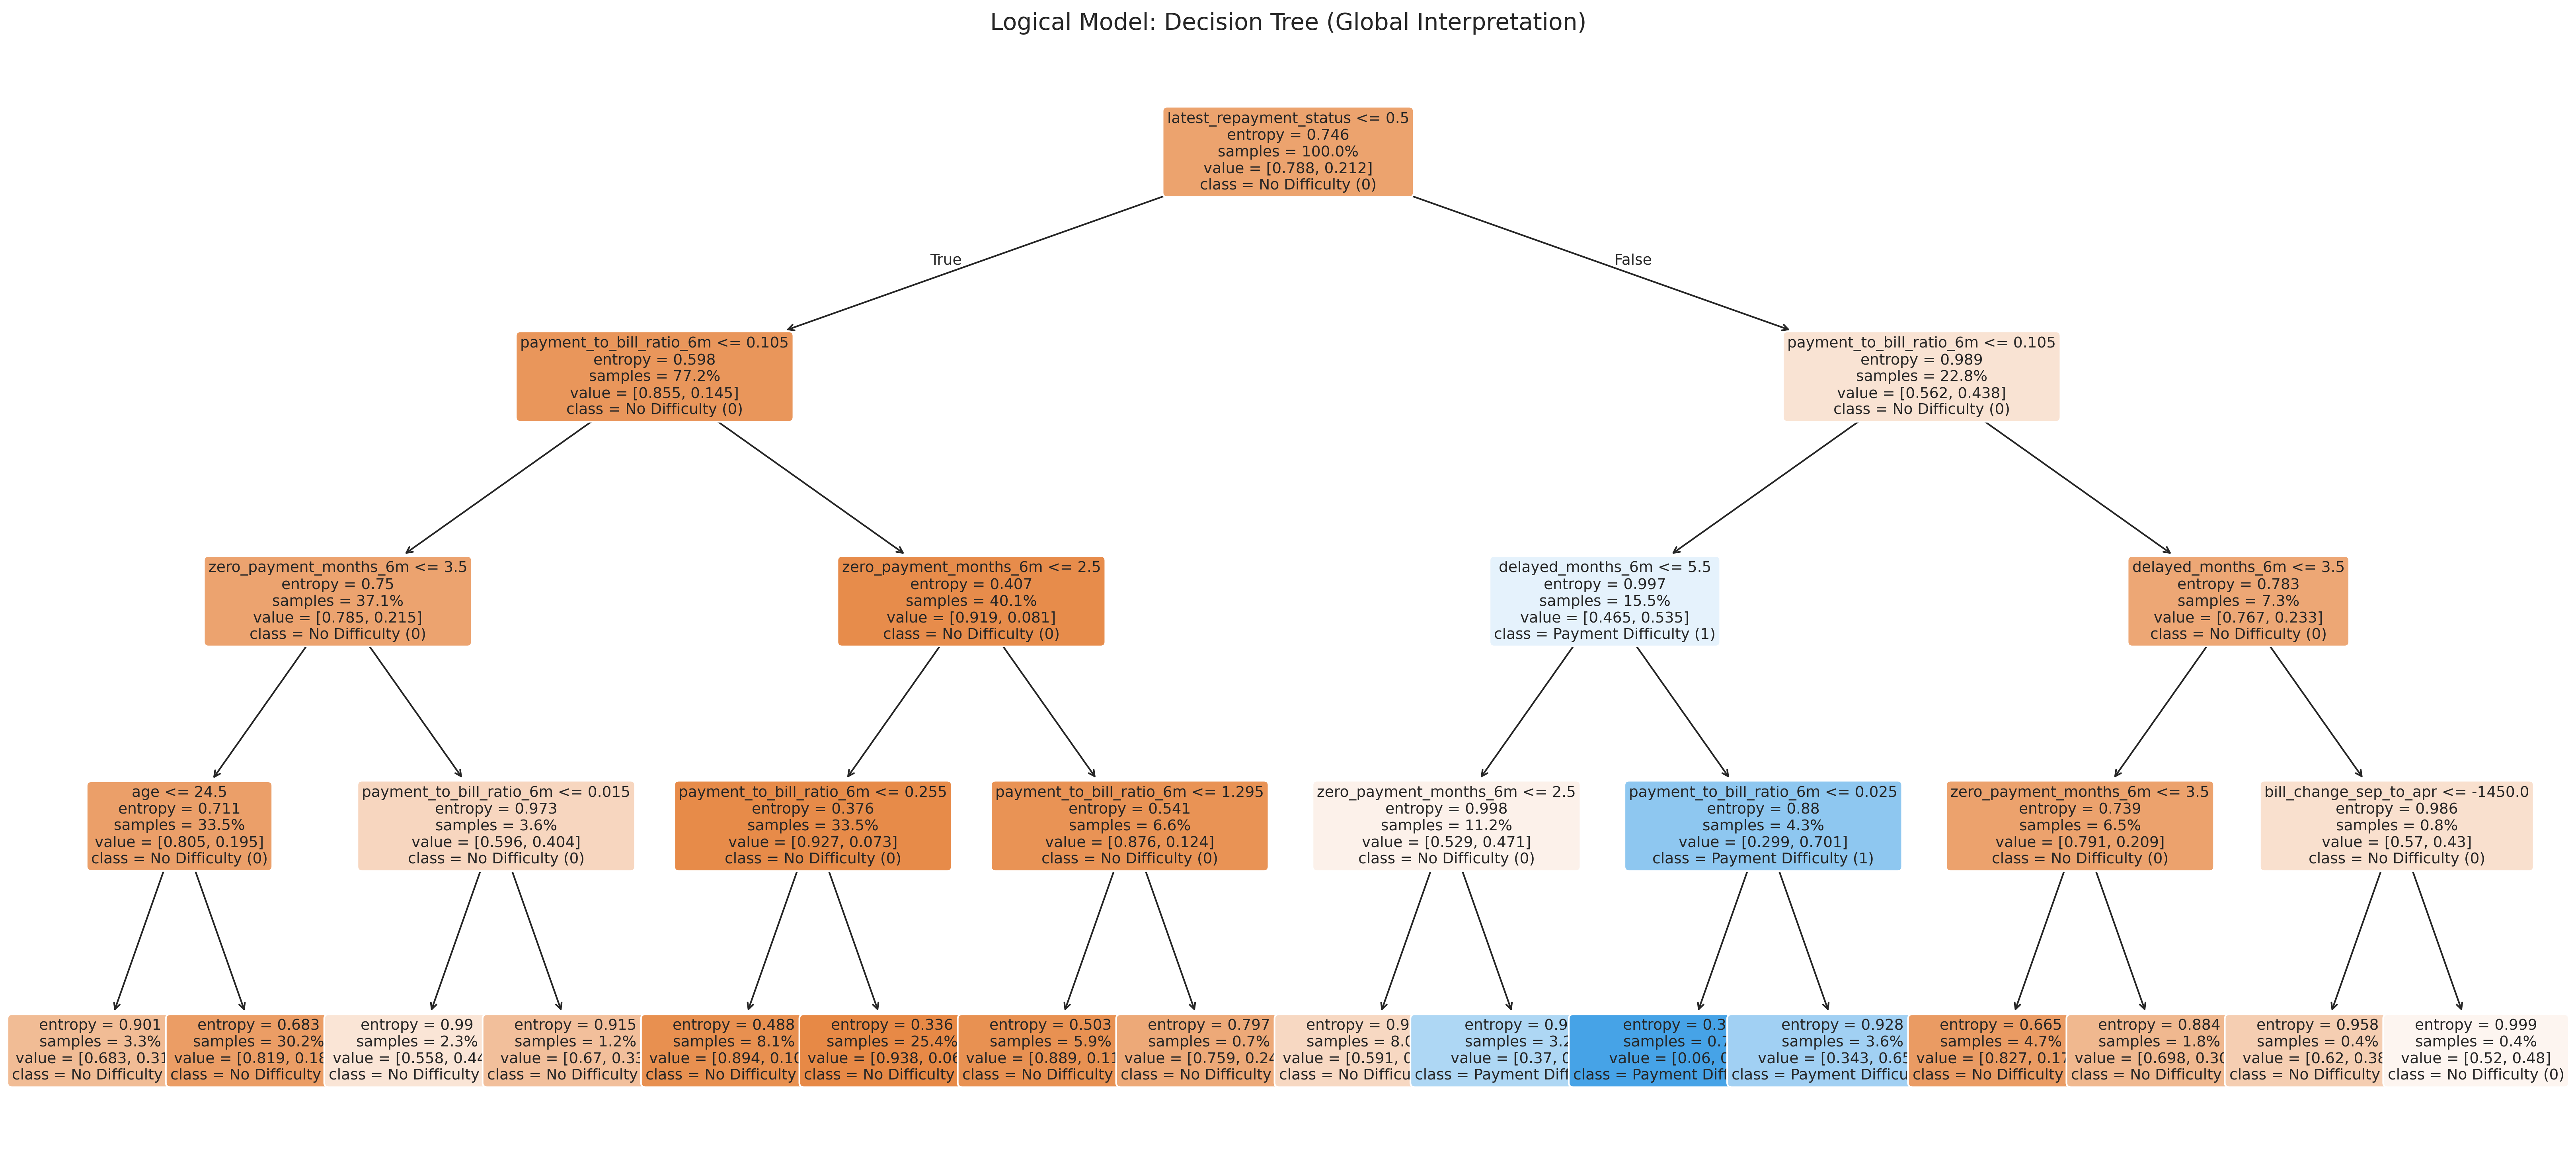

In [8]:
from sklearn.tree import export_text, plot_tree

fitted_tree = best_pipeline.named_steps["classifier"]
feature_names = best_pipeline.named_steps["preprocessor"].get_feature_names_out()
clean_feature_names = [col.replace("cat__", "").replace("num__", "") for col in feature_names]

print("Reglas lógicas del modelo óptimo:")
print(export_text(fitted_tree, feature_names=clean_feature_names))

plt.figure(figsize=(22, 10), dpi=300)
plot_tree(
    fitted_tree,
    feature_names=clean_feature_names,
    class_names=["No Difficulty (0)", "Payment Difficulty (1)"],
    filled=True,
    rounded=True,
    fontsize=9,
    impurity=True,
    proportion=True,
)
plt.title("Logical Model: Decision Tree (Global Interpretation)", fontsize=14)
plt.tight_layout()
plt.savefig("decision_tree.png", dpi=300, bbox_inches="tight")

Métricas de rendimiento

In [9]:
scoring_metrics = ["accuracy", "balanced_accuracy", "recall", "roc_auc"]
cv_results = cross_validate(
    best_pipeline,
    credit_X,
    credit_y,
    cv=cv,
    scoring=scoring_metrics,
    return_train_score=False
)

for metric in scoring_metrics:
    mean_val = cv_results[f"test_{metric}"].mean()
    std_val = cv_results[f"test_{metric}"].std()
    print(f"{metric}: {mean_val:.4f} (+/- {std_val:.4f})")

accuracy: 0.8128 (+/- 0.0022)
balanced_accuracy: 0.6026 (+/- 0.0040)
recall: 0.2374 (+/- 0.0077)
roc_auc: 0.7473 (+/- 0.0050)


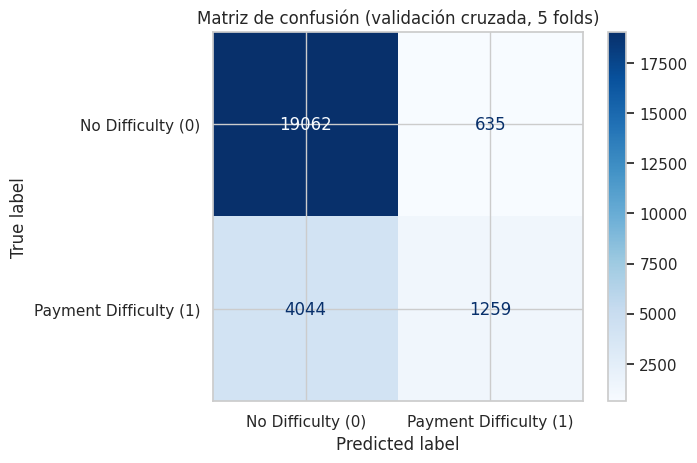

In [10]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay

# Predicciones fuera de fold: cada instancia es predicha por el modelo que no la vio en entrenamiento
y_pred_cv = cross_val_predict(best_pipeline, credit_X, credit_y, cv=cv)

ConfusionMatrixDisplay.from_predictions(
    credit_y, y_pred_cv,
    display_labels=["No Difficulty (0)", "Payment Difficulty (1)"],
    cmap="Blues", values_format="d"
)
plt.title("Matriz de confusión (validación cruzada, 5 folds)")
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

Interpretacion global

In [11]:
fitted_tree = best_pipeline.named_steps["classifier"]
feature_names = best_pipeline.named_steps["preprocessor"].get_feature_names_out()
clean_feature_names = [col.replace("cat__", "").replace("num__", "") for col in feature_names]

Interpretación local

In [12]:
from interpret.glassbox import ClassificationTree
from interpret import show
import pandas as pd
import numpy as np

# Extraer los hiperparámetros óptimos que encontró Grid Search
best_params = grid_search.best_params_
opt_max_depth = best_params['classifier__max_depth']
opt_min_samples_leaf = best_params['classifier__min_samples_leaf']
opt_criterion = best_params['classifier__criterion']

# Transformar el conjunto de entrenamiento
X_train_trans = best_pipeline.named_steps["preprocessor"].transform(credit_X)
if hasattr(X_train_trans, "toarray"):
    X_train_trans = X_train_trans.toarray()

X_train_df = pd.DataFrame(X_train_trans, columns=clean_feature_names)

# Entrenar el árbol de InterpretML con la configuración óptima
interpret_tree = ClassificationTree(
    max_depth=opt_max_depth,
    min_samples_leaf=opt_min_samples_leaf,
    criterion=opt_criterion,
    random_state=42
)
interpret_tree.fit(X_train_df, credit_y)

# Obtener las predicciones del modelo para identificar aciertos y errores
y_pred = best_pipeline.predict(credit_X)

# Definir las condiciones para cada uno de los 4 casos solicitados
mask_c0_correct = (y_pred == 0) & (credit_y == 0)
mask_c0_incorrect = (y_pred == 1) & (credit_y == 0)
mask_c1_correct = (y_pred == 1) & (credit_y == 1)
mask_c1_incorrect = (y_pred == 0) & (credit_y == 1)

# Seleccionar la primera instancia que cumpla cada condición
idx_c0_correct = credit_X[mask_c0_correct].index[0]
idx_c0_incorrect = credit_X[mask_c0_incorrect].index[0]
idx_c1_correct = credit_X[mask_c1_correct].index[0]
idx_c1_incorrect = credit_X[mask_c1_incorrect].index[0]

# Crear un DataFrame con las 4 instancias seleccionadas y renombrar el índice para el gráfico
instancias_locales = credit_X.loc[[idx_c0_correct, idx_c0_incorrect, idx_c1_correct, idx_c1_incorrect]].copy()
instancias_locales.index = [
    'Clase 0 - Prediccion Correcta (True Neg)',
    'Clase 0 - Prediccion Incorrecta (False Pos)',
    'Clase 1 - Prediccion Correcta (True Pos)',
    'Clase 1 - Prediccion Incorrecta (False Neg)'
]

y_locales = credit_y.loc[[idx_c0_correct, idx_c0_incorrect, idx_c1_correct, idx_c1_incorrect]]
y_locales.index = instancias_locales.index

# Transformar las instancias pasando por el preprocesador
X_locales_trans = best_pipeline.named_steps["preprocessor"].transform(instancias_locales)
if hasattr(X_locales_trans, "toarray"):
    X_locales_trans = X_locales_trans.toarray()

X_locales_df = pd.DataFrame(X_locales_trans, columns=clean_feature_names, index=instancias_locales.index)

# Generar y mostrar la explicación local (Widget con desplegable para los 4 casos)
tree_local = interpret_tree.explain_local(X_locales_df, y_locales, name='Comparativa de Predicciones Locales')
show(tree_local)

In [13]:
train["payment_difficulty_next_month"].value_counts(normalize=True)

,proportion
payment_difficulty_next_month,
0,0.78788
1,0.21212


In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from interpret.glassbox import ExplainableBoostingClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, recall_score, precision_score, roc_auc_score

# 1. Pipeline Regresión Logística (Requiere StandardScaler en variables numéricas)
preprocessor_lr = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_cols),
        ("num", StandardScaler(), numeric_cols)
    ]
)

# Búsqueda de hiperparámetro de regularización C en Regresión Logística
lr_base_pipe = Pipeline([
    ("preprocessor", preprocessor_lr),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

grid_lr = GridSearchCV(
    lr_base_pipe,
    param_grid={'classifier__C': [0.001, 0.01, 0.1, 1.0, 10.0]},
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    refit=True
)
grid_lr.fit(credit_X, credit_y)
best_lr_pipeline = grid_lr.best_estimator_
print(f"Mejor C para Regresión Logística: {grid_lr.best_params_['classifier__C']} (ROC-AUC: {grid_lr.best_score_:.4f})")

# 2. Pipeline Explainable Boosting Machine (interactions=0 obligatorio según el enunciado)
ebm_clf = ExplainableBoostingClassifier(interactions=0, random_state=42)
ebm_pipeline = Pipeline([
    ("preprocessor", preprocessor), # Sin escalar para mantener unidades originales en las shape functions
    ("classifier", ebm_clf)
])

# 3. Evaluación comparativa 5-fold CV de los 3 modelos obligatorios
modelos_fase2 = {
    "Decision Tree Classifier": (best_pipeline, "criterion=entropy, max_depth=4, min_samples_leaf=100"),
    "Logistic Regression": (best_lr_pipeline, f"C={grid_lr.best_params_['classifier__C']}, penalty=l2, StandardScaler"),
    "Explainable Boosting Classifier": (ebm_pipeline, "interactions=0")
}

filas_resumen = []
scoring_metrics = ["accuracy", "balanced_accuracy", "recall", "roc_auc"]

for nombre, (pipe, settings) in modelos_fase2.items():
    res_cv = cross_validate(pipe, credit_X, credit_y, cv=cv, scoring=scoring_metrics, n_jobs=-1)
    filas_resumen.append({
        "Classifier": nombre,
        "Key settings": settings,
        "Accuracy": f"{res_cv['test_accuracy'].mean():.4f} +/- {res_cv['test_accuracy'].std():.4f}",
        "Balanced Acc.": f"{res_cv['test_balanced_accuracy'].mean():.4f} +/- {res_cv['test_balanced_accuracy'].std():.4f}",
        "Recall": f"{res_cv['test_recall'].mean():.4f} +/- {res_cv['test_recall'].std():.4f}",
        "ROC-AUC": f"{res_cv['test_roc_auc'].mean():.4f} +/- {res_cv['test_roc_auc'].std():.4f}"
    })

tabla_comparativa_modelos = pd.DataFrame(filas_resumen)
display(tabla_comparativa_modelos)

Mejor C para Regresión Logística: 0.1 (ROC-AUC: 0.7518)


,Classifier,Key settings,Accuracy,Balanced Acc.,Recall,ROC-AUC
0,Decision Tree Classifier,"criterion=entropy, max_depth=4, min_samples_le...",0.8128 +/- 0.0022,0.6026 +/- 0.0040,0.2374 +/- 0.0077,0.7473 +/- 0.0050
1,Logistic Regression,"C=0.1, penalty=l2, StandardScaler",0.8107 +/- 0.0031,0.6040 +/- 0.0062,0.2450 +/- 0.0118,0.7518 +/- 0.0055
2,Explainable Boosting Classifier,interactions=0,0.8186 +/- 0.0021,0.6288 +/- 0.0024,0.2993 +/- 0.0036,0.7760 +/- 0.0049


,Modelo,Umbral,Accuracy,Balanced Acc.,Recall,Precision
1,Decision Tree,0.25,0.7641,0.6863,0.5512,0.4538
2,Decision Tree,0.30,0.7744,0.6822,0.5220,0.4713
5,Decision Tree,0.50,0.8128,0.6026,0.2374,0.6647
7,Logistic Regression,0.25,0.7534,0.6822,0.5584,0.4365
8,Logistic Regression,0.30,0.7800,0.6725,0.4858,0.4815
11,Logistic Regression,0.50,0.8107,0.6040,0.2450,0.6405
13,EBM,0.25,0.7680,0.7004,0.5829,0.4629
14,EBM,0.30,0.7932,0.6903,0.5116,0.5125
17,EBM,0.50,0.8186,0.6288,0.2993,0.6593


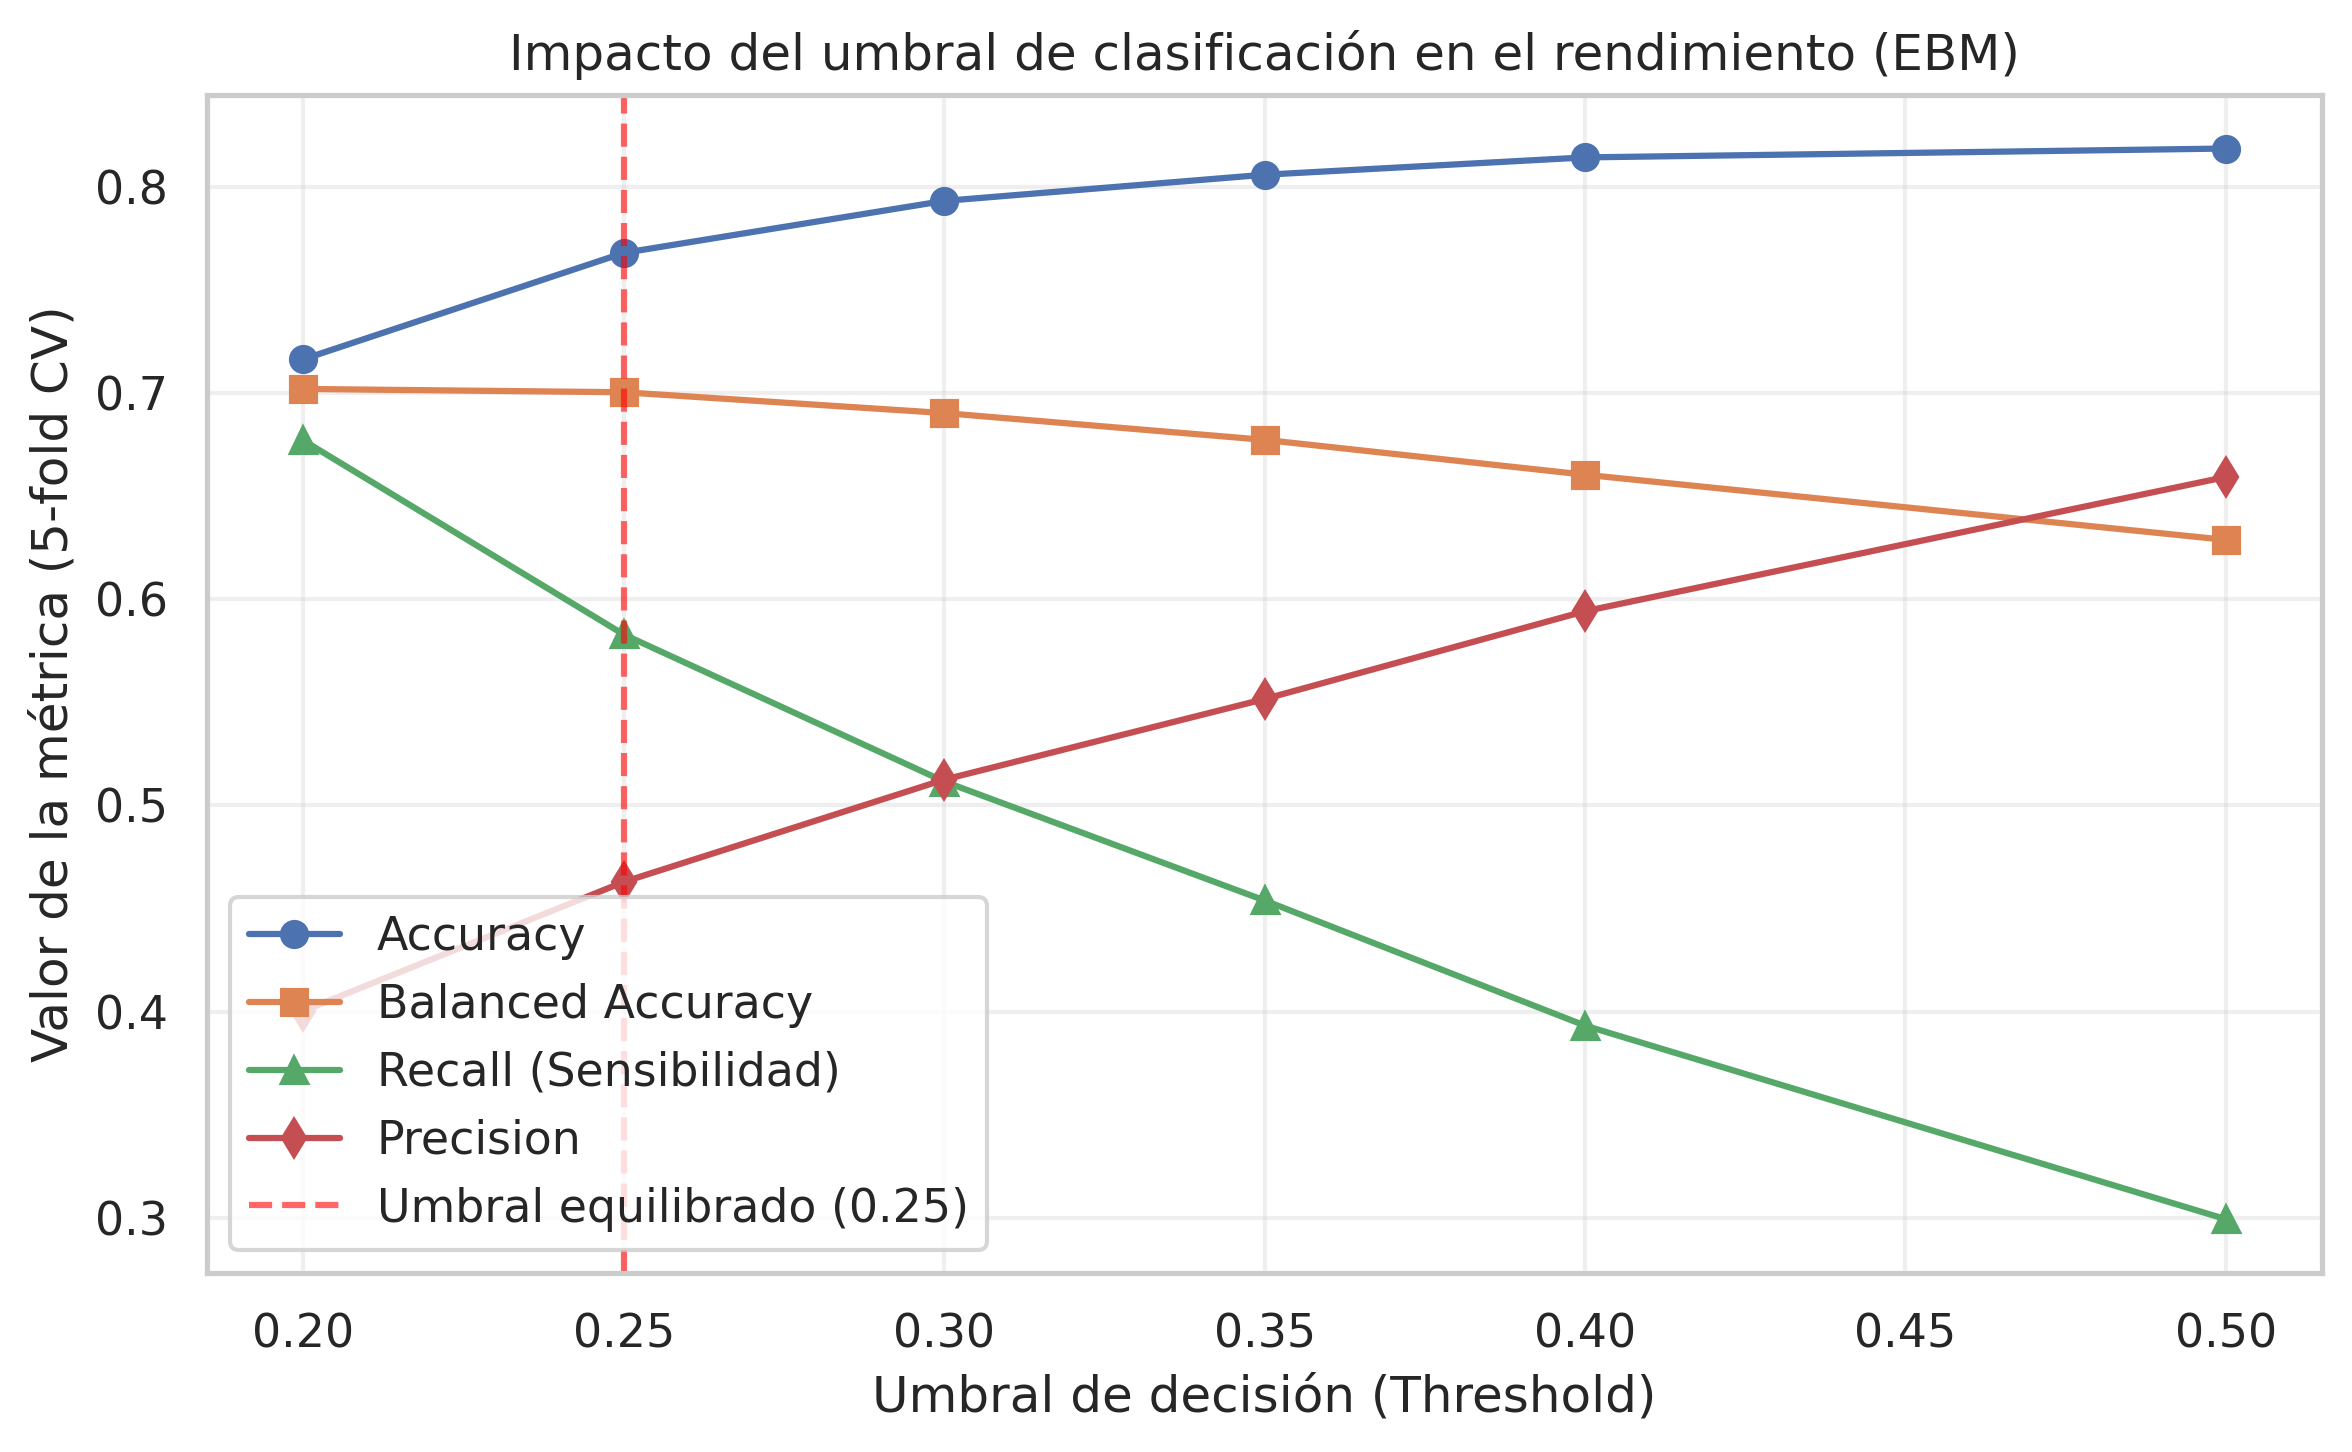

In [15]:
# Probabilidades fuera de partición (out-of-fold) en 5-fold CV para los 3 modelos
oof_proba_tree = cross_val_predict(best_pipeline, credit_X, credit_y, cv=cv, method="predict_proba")[:, 1]
oof_proba_lr   = cross_val_predict(best_lr_pipeline, credit_X, credit_y, cv=cv, method="predict_proba")[:, 1]
oof_proba_ebm  = cross_val_predict(ebm_pipeline, credit_X, credit_y, cv=cv, method="predict_proba")[:, 1]

umbrales = [0.20, 0.25, 0.30, 0.35, 0.40, 0.50]
filas_umbral = []

for nombre_mod, probs in [("Decision Tree", oof_proba_tree), ("Logistic Regression", oof_proba_lr), ("EBM", oof_proba_ebm)]:
    for t in umbrales:
        preds_t = (probs >= t).astype(int)
        filas_umbral.append({
            "Modelo": nombre_mod,
            "Umbral": t,
            "Accuracy": round(accuracy_score(credit_y, preds_t), 4),
            "Balanced Acc.": round(balanced_accuracy_score(credit_y, preds_t), 4),
            "Recall": round(recall_score(credit_y, preds_t), 4),
            "Precision": round(precision_score(credit_y, preds_t), 4)
        })

df_umbrales = pd.DataFrame(filas_umbral)
display(df_umbrales[df_umbrales["Umbral"].isin([0.25, 0.30, 0.50])])

# Gráfico de evolución de métricas según el umbral para EBM
df_ebm_thresh = df_umbrales[df_umbrales["Modelo"] == "EBM"]
plt.figure(figsize=(8, 5), dpi=300)
plt.plot(df_ebm_thresh["Umbral"], df_ebm_thresh["Accuracy"], marker="o", label="Accuracy")
plt.plot(df_ebm_thresh["Umbral"], df_ebm_thresh["Balanced Acc."], marker="s", label="Balanced Accuracy")
plt.plot(df_ebm_thresh["Umbral"], df_ebm_thresh["Recall"], marker="^", label="Recall (Sensibilidad)")
plt.plot(df_ebm_thresh["Umbral"], df_ebm_thresh["Precision"], marker="d", label="Precision")
plt.axvline(0.25, color="red", linestyle="--", alpha=0.6, label="Umbral equilibrado (0.25)")
plt.xlabel("Umbral de decisión (Threshold)")
plt.ylabel("Valor de la métrica (5-fold CV)")
plt.title("Impacto del umbral de clasificación en el rendimiento (EBM)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("threshold_tuning.png", dpi=300, bbox_inches="tight")
plt.show()

Intercepto (Beta_0): -1.6378


,Variable,Coeficiente (Beta),Odds Ratio (exp(Beta))
0,zero_payment_months_6m,0.5056,1.6580
1,repayment_assistance_plan_yes,0.4562,1.5781
2,latest_repayment_status,0.4167,1.5169
3,utilization_sep,0.3929,1.4813
4,delayed_months_6m,0.3140,1.3688
5,education_high_school,0.0823,1.0858
6,education_unknown,0.0748,1.0776
7,credit_limit,0.0674,1.0697
8,average_bill_6m,0.0524,1.0538
9,marital_status_single,0.0312,1.0317


/tmp/ipykernel_1428/2449568056.py:21: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




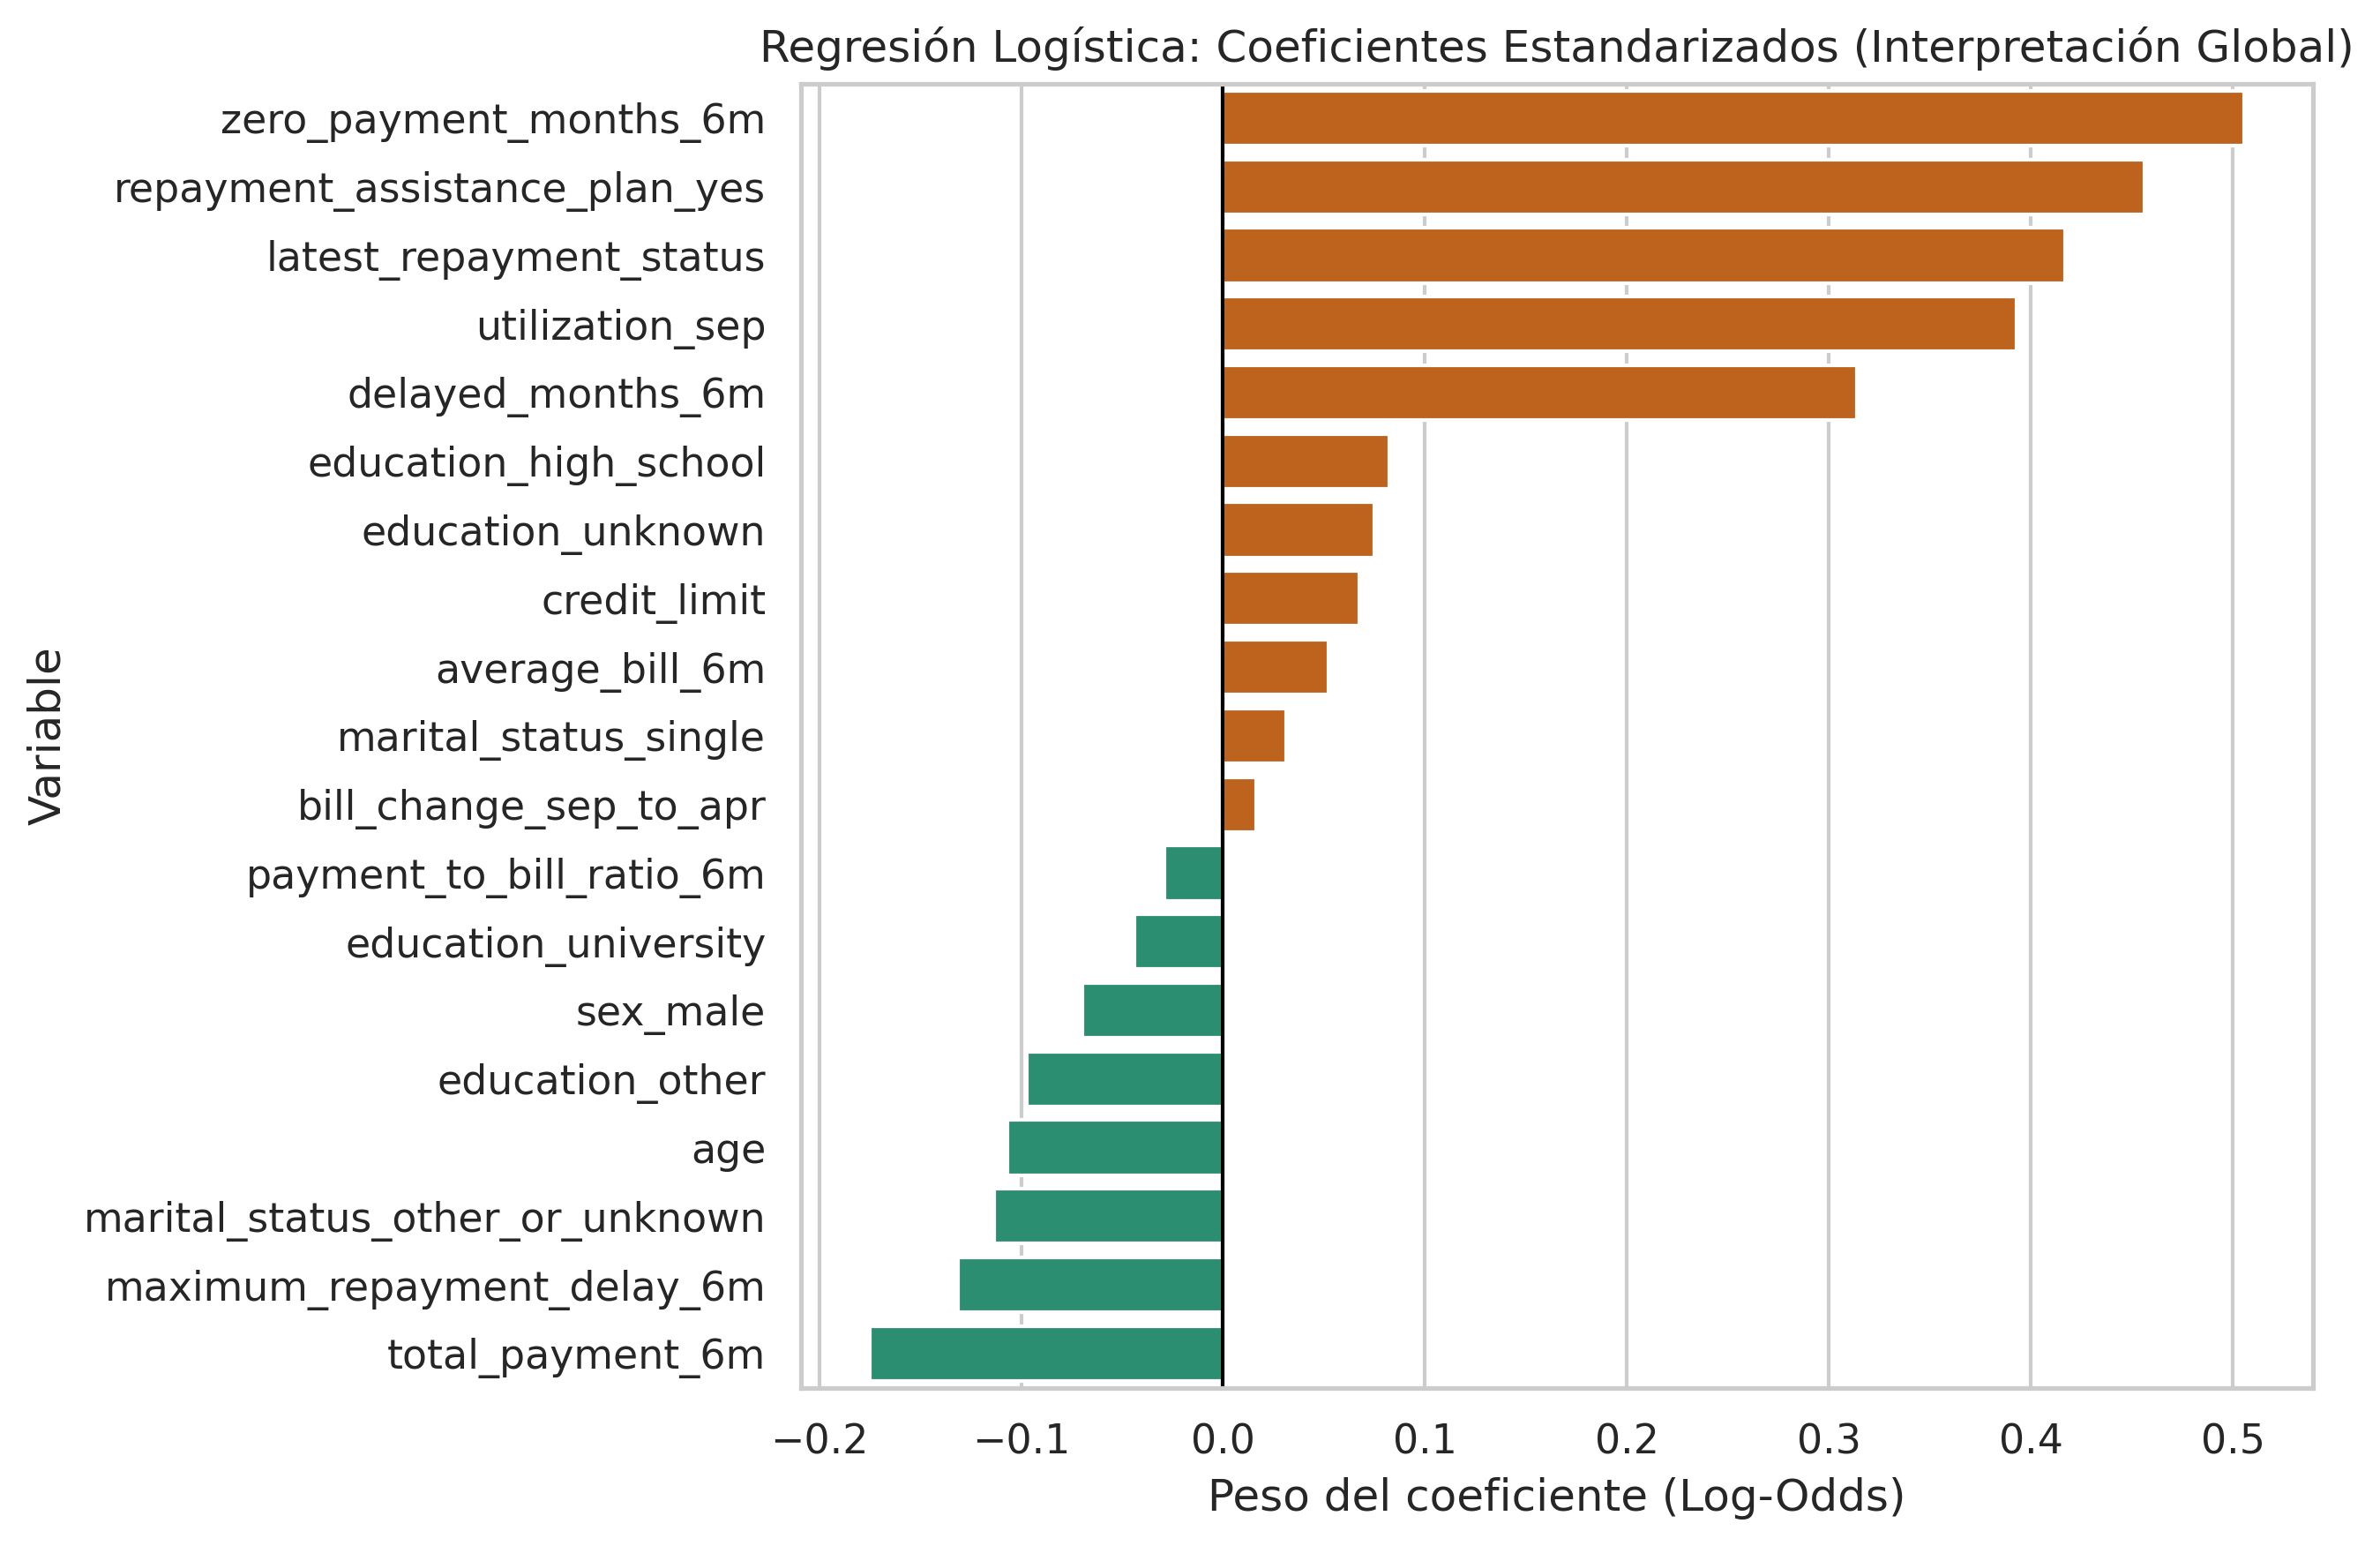

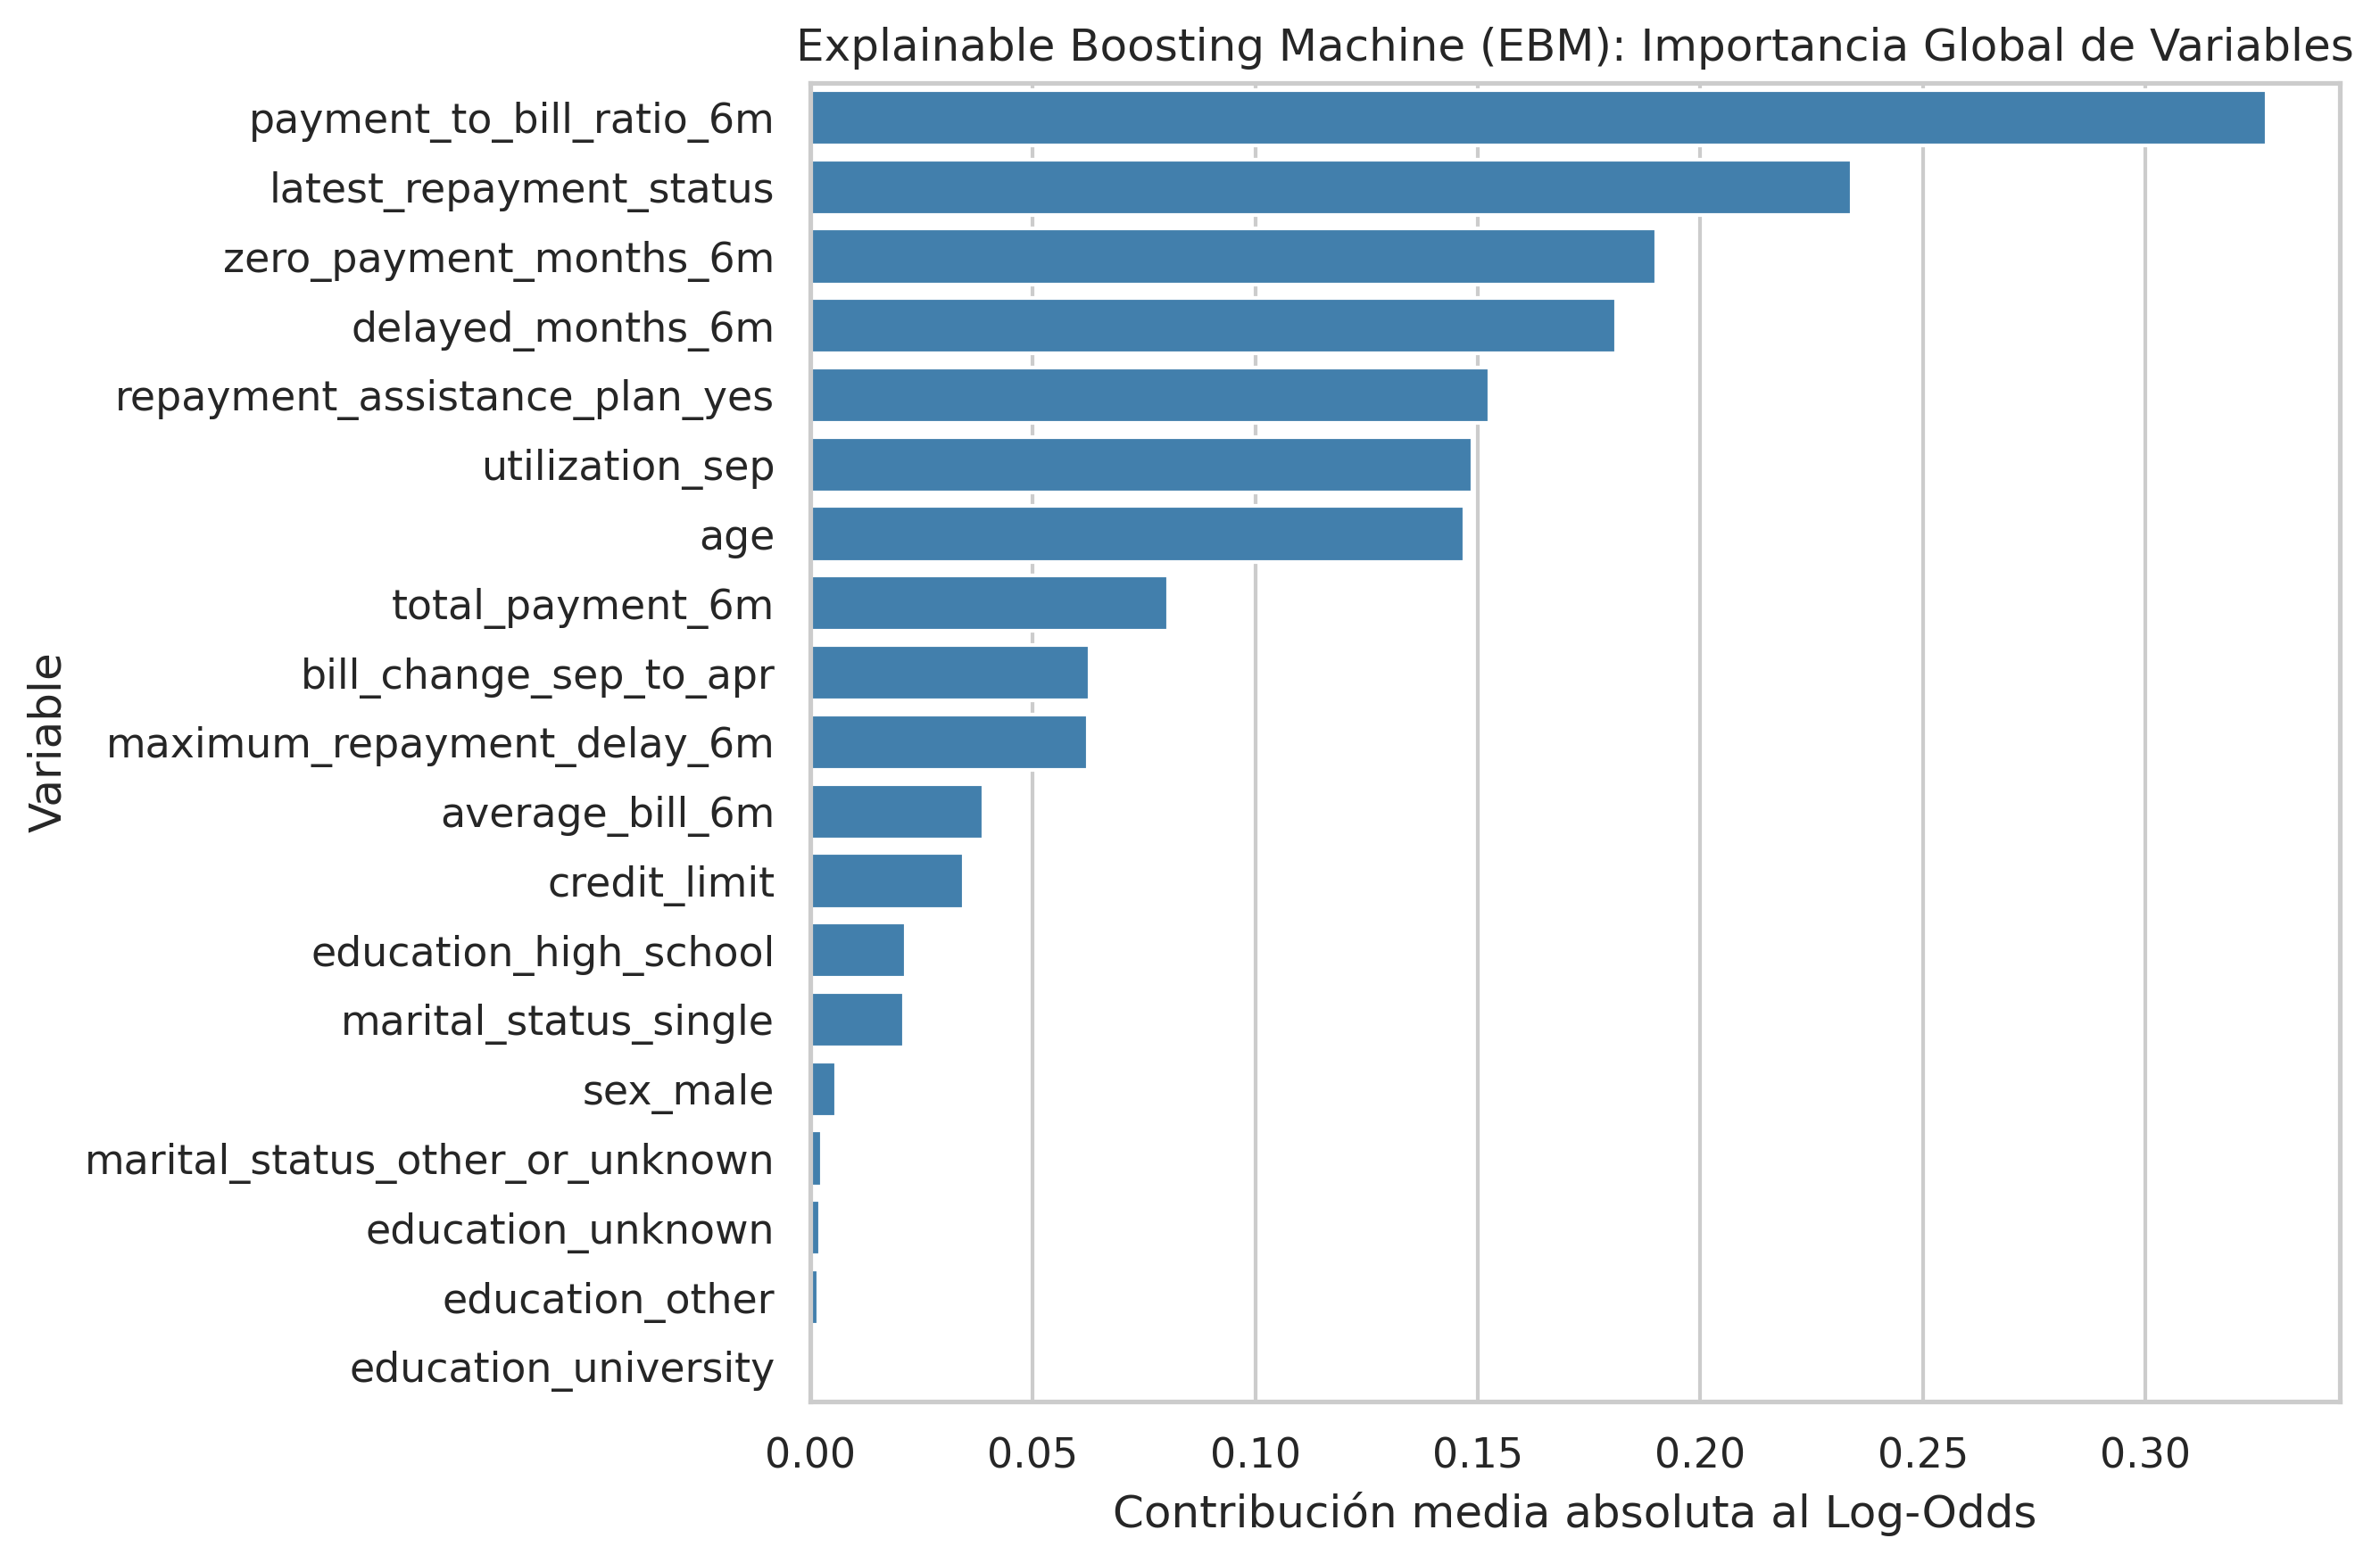

In [16]:
# Ajustar los modelos en todo el conjunto de entrenamiento
best_lr_pipeline.fit(credit_X, credit_y)
ebm_pipeline.fit(credit_X, credit_y)

# --- A. Interpretación Global: Regresión Logística ---
lr_clf = best_lr_pipeline.named_steps["classifier"]
feat_names_lr = [c.replace("cat__", "").replace("num__", "") for c in best_lr_pipeline.named_steps["preprocessor"].get_feature_names_out()]

tabla_coef_lr = pd.DataFrame({
    "Variable": feat_names_lr,
    "Coeficiente (Beta)": lr_clf.coef_[0],
    "Odds Ratio (exp(Beta))": np.exp(lr_clf.coef_[0])
}).sort_values(by="Coeficiente (Beta)", ascending=False).reset_index(drop=True)

print(f"Intercepto (Beta_0): {lr_clf.intercept_[0]:.4f}")
display(tabla_coef_lr.round(4))

# Guardar gráfico de coeficientes de Regresión Logística para el informe en Overleaf
plt.figure(figsize=(9, 6), dpi=300)
colores = ["#d95f02" if c > 0 else "#1b9e77" for c in tabla_coef_lr["Coeficiente (Beta)"]]
sns.barplot(
    data=tabla_coef_lr,
    x="Coeficiente (Beta)",
    y="Variable",
    palette=colores
)
plt.axvline(0, color="black", linewidth=1)
plt.title("Regresión Logística: Coeficientes Estandarizados (Interpretación Global)")
plt.xlabel("Peso del coeficiente (Log-Odds)")
plt.ylabel("Variable")
plt.tight_layout()
plt.savefig("lr_coefficients.png", dpi=300, bbox_inches="tight")
plt.show()

# --- B. Interpretación Global: EBM (Importancias y Shape Functions) ---
X_train_ebm_df = pd.DataFrame(
    ebm_pipeline.named_steps["preprocessor"].transform(credit_X),
    columns=clean_feature_names
)
ebm_interpretable = ExplainableBoostingClassifier(interactions=0, random_state=42)
ebm_interpretable.fit(X_train_ebm_df, credit_y)

# Mostrar el dashboard interactivo de InterpretML para EBM Global
ebm_global_exp = ebm_interpretable.explain_global(name="EBM - Interpretación Global (interactions=0)")
show(ebm_global_exp)

# Exportar gráfico estático de importancias globales de EBM para Overleaf
ebm_imp_df = pd.DataFrame({
    "Variable": ebm_interpretable.feature_names_in_,
    "Importancia Media Absoluta": ebm_interpretable.term_importances()
}).sort_values(by="Importancia Media Absoluta", ascending=False)

plt.figure(figsize=(9, 6), dpi=300)
sns.barplot(data=ebm_imp_df, x="Importancia Media Absoluta", y="Variable", color="#3182bd")
plt.title("Explainable Boosting Machine (EBM): Importancia Global de Variables")
plt.xlabel("Contribución media absoluta al Log-Odds")
plt.ylabel("Variable")
plt.tight_layout()
plt.savefig("ebm_global_importance.png", dpi=300, bbox_inches="tight")
plt.show()

In [17]:
# Índices exactos seleccionados en la Fase I: [0 (TN), 8 (FP), 23 (TP), 12 (FN)]
indices_4_casos = [idx_c0_correct, idx_c0_incorrect, idx_c1_correct, idx_c1_incorrect]
X_4_raw = credit_X.loc[indices_4_casos]
y_4_raw = credit_y.loc[indices_4_casos]

# Probabilidades de impago predichas por cada uno de los 3 modelos
p_tree_4 = best_pipeline.predict_proba(X_4_raw)[:, 1]
p_lr_4   = best_lr_pipeline.predict_proba(X_4_raw)[:, 1]
p_ebm_4  = ebm_pipeline.predict_proba(X_4_raw)[:, 1]

tabla_comparativa_local = pd.DataFrame({
    "Caso (en Árbol)": ["TN (Caso 0)", "FP (Caso 1)", "TP (Caso 2)", "FN (Caso 3)"],
    "row_id": train.loc[indices_4_casos, "row_id"].values,
    "Clase Real": y_4_raw.values,
    "P(impago) Árbol": np.round(p_tree_4, 3),
    "Pred. Árbol": (p_tree_4 >= 0.5).astype(int),
    "P(impago) LogReg": np.round(p_lr_4, 3),
    "Pred. LogReg": (p_lr_4 >= 0.5).astype(int),
    "P(impago) EBM": np.round(p_ebm_4, 3),
    "Pred. EBM": (p_ebm_4 >= 0.5).astype(int)
})

print("Comparativa de predicciones locales en las 4 instancias para los 3 modelos:")
display(tabla_comparativa_local)

# Mostrar explicaciones locales de EBM en InterpretML para las 4 instancias
X_locales_ebm_df = pd.DataFrame(
    ebm_pipeline.named_steps["preprocessor"].transform(instancias_locales),
    columns=clean_feature_names,
    index=instancias_locales.index
)
ebm_local_exp = ebm_interpretable.explain_local(X_locales_ebm_df, y_locales, name="EBM - 4 Instancias Locales")
show(ebm_local_exp)

Comparativa de predicciones locales en las 4 instancias para los 3 modelos:


,Caso (en Árbol),row_id,Clase Real,P(impago) Árbol,Pred. Árbol,P(impago) LogReg,Pred. LogReg,P(impago) EBM,Pred. EBM
0,TN (Caso 0),CR26-120473,0,0.181,0,0.077,0,0.125,0
1,FP (Caso 1),CR26-108799,0,0.630,1,0.441,0,0.505,1
2,TP (Caso 2),CR26-122978,1,0.630,1,0.516,1,0.640,1
3,FN (Caso 3),CR26-111201,1,0.409,0,0.320,0,0.466,0


In [18]:
# Predecir sobre las 5.000 instancias de test.csv usando el mejor modelo (EBM)
X_test_features = test.drop(columns=[id_col])
predicciones_test = ebm_pipeline.predict(X_test_features)

# Crear copia del dataframe de test original y añadir la columna objetivo al final
test_entregable = test.copy()
test_entregable[target_col] = predicciones_test

# Comprobación de seguridad
print("Dimensiones de test.csv completado:", test_entregable.shape)
print("Distribución de predicciones en test.csv:")
print(test_entregable[target_col].value_counts(normalize=True).round(4))

# Guardar archivo CSV
test_entregable.to_csv("test.csv", index=False)

# Descargar automáticamente si estás en Google Colab
if 'google.colab' in sys.modules:
    from google.colab import files
    files.download("test.csv")

Dimensiones de test.csv completado: (5000, 17)
Distribución de predicciones en test.csv:
payment_difficulty_next_month
0    0.9044
1    0.0956
Name: proportion, dtype: float64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
from interpret.glassbox import LogisticRegression as InterpretLR

# Escalar los datos para el wrapper interpretable de Regresión Logística
X_train_lr_df = pd.DataFrame(best_lr_pipeline.named_steps["preprocessor"].transform(credit_X), columns=feat_names_lr)
X_local_lr_df = pd.DataFrame(best_lr_pipeline.named_steps["preprocessor"].transform(instancias_locales), columns=feat_names_lr, index=instancias_locales.index)

interpret_lr = InterpretLR(C=0.1, max_iter=1000, random_state=42)
interpret_lr.fit(X_train_lr_df, credit_y)
show(interpret_lr.explain_local(X_local_lr_df, y_locales, name="Regresión Logística - 4 Instancias Locales"))

In [20]:
import pandas as pd
df_test = pd.read_csv("test.csv")
print("Filas y columnas:", df_test.shape)
print("Última columna añadida:", df_test.columns[-1])
display(df_test.head(3))

Filas y columnas: (5000, 17)
Última columna añadida: payment_difficulty_next_month


,row_id,credit_limit,sex,education,marital_status,age,latest_repayment_status,maximum_repayment_delay_6m,delayed_months_6m,average_bill_6m,bill_change_sep_to_apr,total_payment_6m,payment_to_bill_ratio_6m,zero_payment_months_6m,utilization_sep,repayment_assistance_plan,payment_difficulty_next_month
0,CR26-128173,50000,male,graduate_school,single,25,0,0,0,27700,31600,21700,0.13,0,0.8,no,0
1,CR26-102911,280000,female,university,married,41,1,1,1,100,300,600,0.63,4,0.0,no,0
2,CR26-104960,420000,male,university,married,38,0,0,0,262500,108200,56200,0.04,0,0.7,no,0


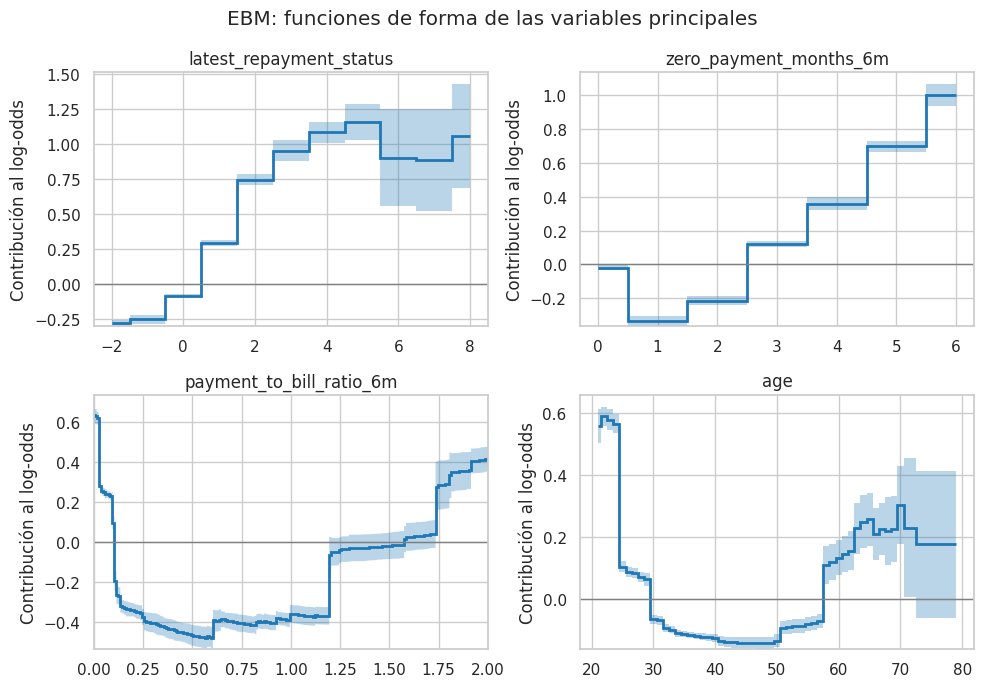

In [24]:
# Funciones de forma del EBM para las variables más importantes
ebm_global_exp = ebm_interpretable.explain_global()
variables = ["latest_repayment_status", "zero_payment_months_6m",
             "payment_to_bill_ratio_6m", "age"]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, var in zip(axes.ravel(), variables):
    datos = ebm_global_exp.data(ebm_interpretable.term_names_.index(var))
    bordes = np.asarray(datos["names"], dtype=float)
    ax.stairs(datos["upper_bounds"], bordes, baseline=datos["lower_bounds"],
              fill=True, alpha=0.3, color="tab:blue")
    ax.stairs(datos["scores"], bordes, color="tab:blue", linewidth=2, baseline=None)
    ax.axhline(0, color=".5", linewidth=1)
    ax.set_title(var)
    ax.set_ylabel("Contribución al log-odds")
axes[1, 0].set_xlim(0, 2)  # el ratio llega hasta 5, pero casi todos los datos están por debajo de 2
plt.suptitle("EBM: funciones de forma de las variables principales")
plt.tight_layout()
plt.savefig("ebm_shape_functions.png", dpi=300, bbox_inches="tight")
plt.show()